# A water budget with a conservation check

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/09-water.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/09-water.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `7f7e355586bed5b10f0cfb64b8fb5b5e163e6246deaf6651b817bd9b12a7ea5e`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# A water budget with a conservation check

**Lesson 09 · Original synthetic data · Independent educational project**

## Objectives

Implement a toy catchment bucket; close the mass balance.

[Previous](08-extremes.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/09-water.ipynb) · [Next](10-wind.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=09-water.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

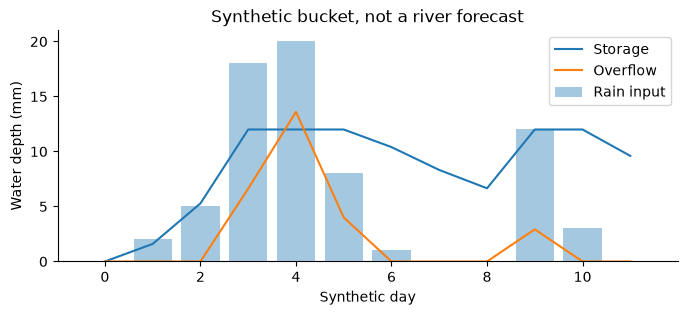

Budget residual: -4.33e-15 mm


In [2]:
rain = np.array([0, 2, 5, 18, 20, 8, 1, 0, 0, 12, 3, 0], dtype=float)
storage, runoff, drainage = lab.flood_bucket(rain, capacity=12, drainage=.2)
delta = np.diff(np.r_[0, storage])
assert np.allclose(rain, delta + runoff + drainage)
assert storage.min() >= 0 and storage.max() <= 12
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(np.arange(len(rain)), rain, alpha=.4, label="Rain input")
ax.plot(storage, label="Storage")
ax.plot(runoff, label="Overflow")
ax.set(xlabel="Synthetic day", ylabel="Water depth (mm)", title="Synthetic bucket, not a river forecast")
ax.legend(); plt.show()
print(f"Budget residual: {(rain-delta-runoff-drainage).sum():.2e} mm")

## Exercise

Double storage capacity and compare total overflow. Keep rainfall fixed so the scenario comparison has a clear cause.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

Conservation is necessary but not sufficient for realism. This bucket omits routing, soil heterogeneity, snow and infrastructure; overflow is not calibrated river discharge.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://destine.ecmwf.int/weather-induced-extremes-digital-twin/) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).